# Why the method looks like this: a walkthrough of the Gidea–Katz pipeline on point clouds

Papers that apply TDA to prices (Gidea & Katz 2018 and the reports that copy it) all go through the same steps *before* any stock data appears:

> prices → log returns → **sliding window** point clouds → **Vietoris–Rips** filtration → **$H_1$** persistence diagram → **persistence landscape** → **$L^p$ norm** → **rolling variance / ACF(1) / low-frequency power** → **Kendall $\tau$**

This notebook asks, for each step, *why that step and not something else*, and answers with a small experiment on synthetic point clouds. The companion PDF (`06_Method_Walkthrough.pdf`) collects the figures and the explanations.
Mathematical background is in the study notes `01_Homology_for_TDA.pdf` and `02_Persistent_Homology_for_TDA.pdf`; the shared code is in `tda_utils.py`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from ripser import ripser
from persim import plot_diagrams, wasserstein, bottleneck
import tda_utils as T
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 160, "savefig.bbox": "tight"})
os.makedirs("figures/walkthrough", exist_ok=True)
rng = np.random.default_rng(0)
def save(name): plt.savefig(f"figures/walkthrough/{name}.png"); plt.show()

## 1. Why log returns, and why a point cloud at all?

A price series is a curve; TDA needs a *set of points with distances*. The paper's choice is to make **each day one point** whose coordinates are the returns of several indices that day.
Two things have to be true for distances between days to mean anything:

1. the coordinates must be *comparable across time* (a 1% move in 2000 and in 2024 should be the same distance), so we use returns, not prices, and log returns so that up and down moves are symmetric: $r_t=\ln(P_t/P_{t-1})$;
2. the coordinates must be *comparable across axes*. Index returns of similar markets already are (all are daily % moves). If an axis has a different unit (a bond index, an FX volatility), it has to be rescaled first, otherwise one axis dominates every distance.

Below: the same four days as prices, as raw returns and as returns of indices with very different scales. Only the middle picture is a sensible cloud.

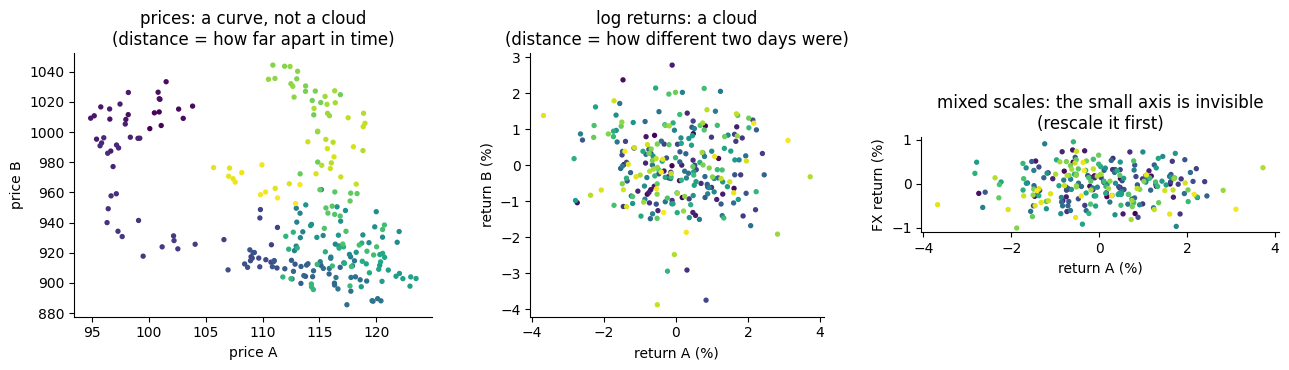

In [2]:
n = 250
pA = 100 * np.exp(np.cumsum(rng.normal(0.0005, 0.012, n)))      # a stock index
pB = 1000 * np.exp(np.cumsum(rng.normal(0.0003, 0.010, n)))     # another index
fx = 1300 * np.exp(np.cumsum(rng.normal(0, 0.004, n)))          # an FX rate: much smaller daily moves
rA, rB, rF = [np.diff(np.log(p)) * 100 for p in (pA, pB, fx)]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(pA[1:], pB[1:], s=8, c=np.arange(n - 1), cmap="viridis"); axes[0].set_xlabel("price A"); axes[0].set_ylabel("price B"); axes[0].set_title("prices: a curve, not a cloud\n(distance = how far apart in time)")
axes[1].scatter(rA, rB, s=8, c=np.arange(n - 1), cmap="viridis"); axes[1].set_xlabel("return A (%)"); axes[1].set_ylabel("return B (%)"); axes[1].set_aspect("equal"); axes[1].set_title("log returns: a cloud\n(distance = how different two days were)")
axes[2].scatter(rA, rF, s=8, c=np.arange(n - 1), cmap="viridis"); axes[2].set_xlabel("return A (%)"); axes[2].set_ylabel("FX return (%)"); axes[2].set_aspect("equal"); axes[2].set_title("mixed scales: the small axis is invisible\n(rescale it first)")
plt.tight_layout(); save("01_why_returns")

## 2. Why a sliding window?

Persistent homology summarizes a *set* of points. To get a time series of summaries we need a set for every day: the **last $w$ days**. Sliding the window one day at a time gives one cloud, one diagram and one number per trading day.

The choice of $w$ is a trade-off:
- **too small**: a cloud of 20 points can barely form a loop, the diagram is almost all noise, and the norm jumps around;
- **too large**: the cloud mixes old and new regimes, so a change shows up late and diluted.

Experiment: two correlated return series that switch from a calm, tightly correlated regime to a stressed, decorrelated regime at day 400. We compute $\|\lambda\|_1$ of $H_1$ for $w\in\{20,50,100,200\}$.

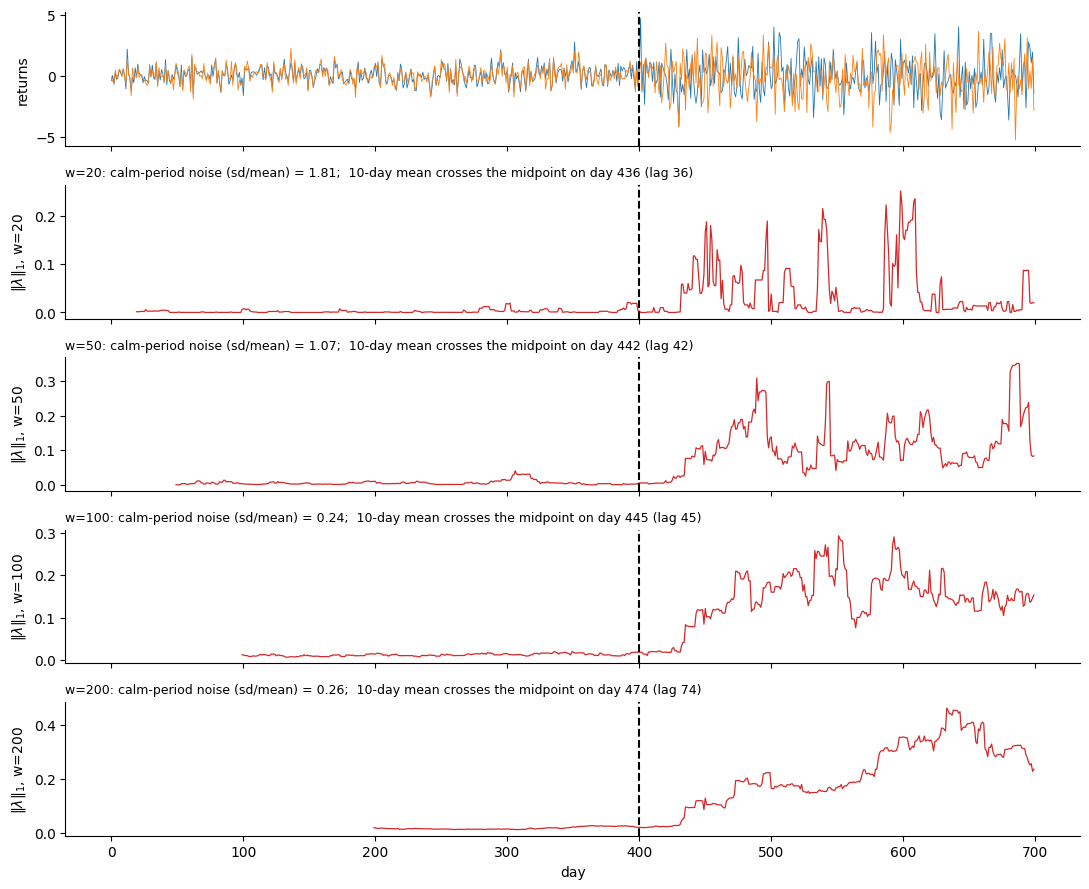

In [3]:
def regime_series(n_calm=400, n_stress=300, seed=1):
    r = np.random.default_rng(seed)
    calm = r.multivariate_normal([0, 0], [[1, .85], [.85, 1]], n_calm) * 0.7
    stress = r.multivariate_normal([0, 0], [[1, .1], [.1, 1]], n_stress) * 1.5
    return pd.DataFrame(np.r_[calm, stress], columns=["A", "B"])

S = regime_series()
fig, axes = plt.subplots(5, 1, figsize=(11, 9), sharex=True)
axes[0].plot(S.values, lw=.6); axes[0].axvline(400, color="k", ls="--"); axes[0].set_ylabel("returns")
for ax, w in zip(axes[1:], [20, 50, 100, 200]):
    ns = T.norm_series(S, w=w)["L1"]
    ax.plot(ns, color="C3", lw=.9); ax.axvline(400, color="k", ls="--"); ax.set_ylabel(f"$\\|\\lambda\\|_1$, w={w}")
    calm, stress = ns.loc[:399], ns.loc[450:]
    noise = calm.std() / calm.mean()                                   # how jumpy the norm is when nothing happens
    mid = (calm.mean() + stress.mean()) / 2
    sm = ns.rolling(10).mean(); hit = sm.index[(sm > mid) & (sm.index >= 400)]
    ax.set_title(f"w={w}: calm-period noise (sd/mean) = {noise:.2f};  10-day mean crosses the midpoint on day {hit[0]} (lag {hit[0]-400})", fontsize=9, loc="left")
axes[-1].set_xlabel("day"); plt.tight_layout(); save("02_window_size")

Small windows are noisy even when nothing happens (the calm-period noise ratio falls as $w$ grows) and large windows detect the change only after most of the window is filled with the new regime (the lag grows with $w$).
$w=50$ (the paper's choice, about one trading quarter) is the usual compromise: enough points for loops to form, short enough to react within a few weeks.

## 3. Why Vietoris–Rips, why Euclidean distance, why $H_1$?

**Rips, not Čech.** The Čech complex is the "correct" one (nerve theorem), but it needs to test whether balls have a common point; Rips only needs the distance matrix and is sandwiched between two Čech complexes, so its diagram is wrong by at most a factor 2 in scale. For 50–100 points per day over 7,000 days, cost decides.

**Euclidean distance.** Returns are already on a common scale, and the Euclidean distance between two days is the natural "how differently did the indices move on those two days".

**$H_1$, not $H_0$ or $H_2$.** $H_0$ of a Rips filtration is single-linkage clustering: its bars are just the nearest-neighbour distances, which mostly measure how *spread out* the cloud is, i.e. volatility. $H_2$ needs many more points than a 50-day window has in 3–4 dimensions. $H_1$ (loops) is the lowest dimension that sees *shape* beyond spread: a loop means the joint returns circled around an empty region.

Experiment: a tight blob, a wide blob and a ring with the same spread. $H_0$ cannot tell the wide blob from the ring; $H_1$ can.

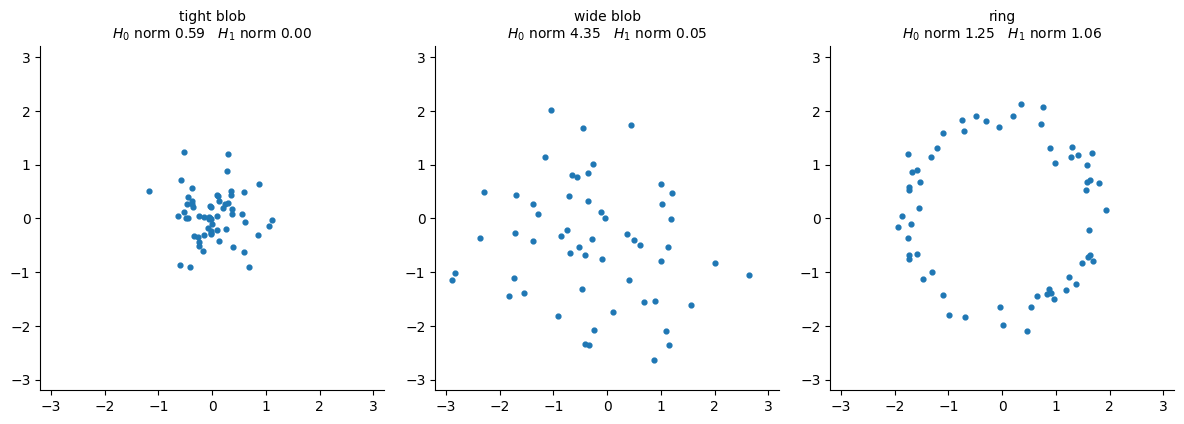

In [4]:
def h_norms(P):
    d = ripser(P, maxdim=1)["dgms"]
    h0 = d[0][np.isfinite(d[0][:, 1])]
    return T.landscape_norm(h0, 1), T.landscape_norm(d[1], 1)

tight = rng.normal(0, 0.5, (60, 2))
wide = rng.normal(0, 1.5, (60, 2))
t = rng.uniform(0, 2 * np.pi, 60); ring = np.c_[np.cos(t), np.sin(t)] * 1.8 + rng.normal(0, 0.15, (60, 2))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, P) in zip(axes, [("tight blob", tight), ("wide blob", wide), ("ring", ring)]):
    n0, n1 = h_norms(P)
    ax.scatter(P[:, 0], P[:, 1], s=12); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
    ax.set_title(f"{name}\n$H_0$ norm {n0:.2f}   $H_1$ norm {n1:.2f}", fontsize=10)
plt.tight_layout(); save("03_h0_vs_h1")

## 4. Why a persistence landscape instead of the diagram?

A diagram is a *multiset of points*: you cannot add two diagrams, average twenty of them, or compute a variance of diagrams over time. Bubenik's landscape turns the diagram into a **function** $\lambda=(\lambda_1,\lambda_2,\dots)$ with $\lambda_k(\epsilon)$ = the $k$-th largest tent at $\epsilon$.
Functions live in a vector space: averages, norms and confidence bands all make sense, and the map diagram → landscape is **stable** ($\sup|\lambda_k-\lambda'_k|\le d_B$).

Experiment: twenty noisy samples of the same ring. Their diagrams are twenty different point sets; their landscapes can be averaged into one function with a confidence band.

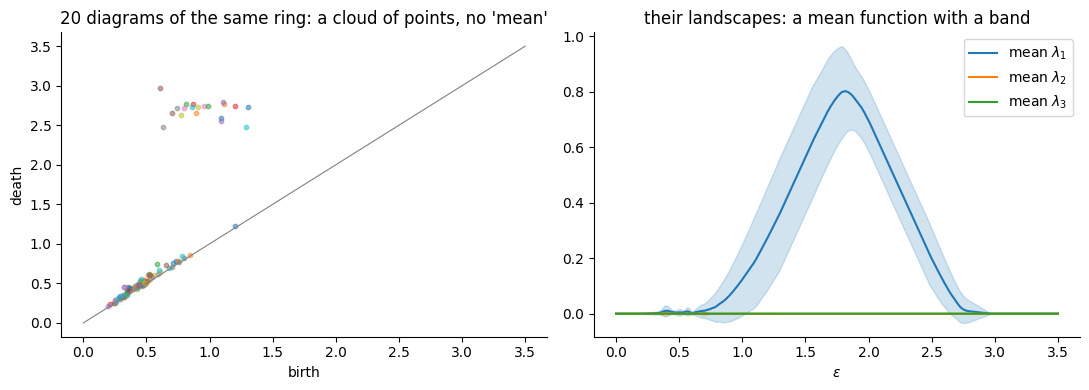

In [5]:
grid = np.linspace(0, 3.5, 300); lams = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i in range(20):
    t = rng.uniform(0, 2 * np.pi, 60); P = np.c_[np.cos(t), np.sin(t)] * 1.8 + rng.normal(0, 0.2, (60, 2))
    dg = T.rips_h1(P); axes[0].scatter(dg[:, 0], dg[:, 1], s=10, alpha=.5)
    lams.append(T.landscape(dg, grid, k_max=3))
axes[0].plot([0, 3.5], [0, 3.5], color="gray", lw=.8); axes[0].set_xlabel("birth"); axes[0].set_ylabel("death"); axes[0].set_title("20 diagrams of the same ring: a cloud of points, no 'mean'")
L = np.array(lams)
for k, c in zip(range(3), ["C0", "C1", "C2"]):
    m, s = L[:, k].mean(0), L[:, k].std(0)
    axes[1].plot(grid, m, color=c, label=f"mean $\\lambda_{k+1}$"); axes[1].fill_between(grid, m - s, m + s, color=c, alpha=.2)
axes[1].set_xlabel("$\\epsilon$"); axes[1].legend(); axes[1].set_title("their landscapes: a mean function with a band")
plt.tight_layout(); save("04_landscape_mean")

## 5. Why the $L^p$ norm, and why $p=1$ and $p=2$?

The norm $\|\lambda\|_p=\big(\sum_k\int|\lambda_k|^p\big)^{1/p}$ collapses the landscape to one number per day. With lifetimes $\ell_j=d_j-b_j$,

$$\|\lambda\|_1=\tfrac14\sum_j\ell_j^2,\qquad \|\lambda\|_2=\Big(\tfrac1{12}\sum_j\ell_j^3\Big)^{1/2}.$$

So **$\|\lambda\|_1$** counts every loop, weighted by the square of its lifetime, and **$\|\lambda\|_2$** is dominated by the longest bars. The paper reports both because they answer slightly different questions: "how much loop structure overall" vs "is there one big loop".

Experiment: diagram A has one long bar; diagram B is A plus twenty short bars (the kind of noise a real window always has).

In [6]:
A = np.array([[0.5, 2.3]])
B = np.r_[A, [[0.3 + 0.1 * i, 0.3 + 0.1 * i + 0.2] for i in range(20)]]
for name, D in [("A: one loop, lifetime 1.8", A), ("B: the same loop + 20 loops of lifetime 0.2", B)]:
    print(f"{name:48s} L1 = {T.landscape_norm(D, 1):.3f}   L2 = {T.landscape_norm(D, 2):.3f}")
print("B/A - 1:  L1 %+.0f%%   L2 %+.1f%%" % (100 * (T.landscape_norm(B, 1) / T.landscape_norm(A, 1) - 1), 100 * (T.landscape_norm(B, 2) / T.landscape_norm(A, 2) - 1)))

A: one loop, lifetime 1.8                        L1 = 0.810   L2 = 0.697
B: the same loop + 20 loops of lifetime 0.2      L1 = 1.010   L2 = 0.707
B/A - 1:  L1 +25%   L2 +1.4%


Twenty small loops raise $\|\lambda\|_1$ by a quarter but $\|\lambda\|_2$ by about one percent: $\|\lambda\|_2$ effectively sees only the dominant loop, $\|\lambda\|_1$ also counts the background. In the finance pipeline this is why the two norms usually move together but $\|\lambda\|_1$ is the noisier of the two and $\|\lambda\|_2$ reacts mainly to days with one big loop.

**The scale caveat, measured.** The Rips filtration is built from raw distances, so multiplying every return by $c$ multiplies each lifetime by $c$ and $\|\lambda\|_1$ by $c^2$:

In [7]:
P = rng.multivariate_normal([0, 0], [[1, .5], [.5, 1]], 50)
for c in [0.5, 1, 2, 3]:
    print(f"returns x {c}:  L1 = {T.landscape_norm(T.rips_h1(P * c), 1):.4f}   (ratio to c=1: {T.landscape_norm(T.rips_h1(P * c), 1) / T.landscape_norm(T.rips_h1(P), 1):.2f}, c^2 = {c*c})")

returns x 0.5:  L1 = 0.0058   (ratio to c=1: 0.25, c^2 = 0.25)
returns x 1:  L1 = 0.0231   (ratio to c=1: 1.00, c^2 = 1)
returns x 2:  L1 = 0.0923   (ratio to c=1: 4.00, c^2 = 4)
returns x 3:  L1 = 0.2077   (ratio to c=1: 9.00, c^2 = 9)


This is the single most important thing to know when reading a landscape-norm plot of returns: **a volatility spike is a norm spike**. Three ways people deal with it:

| option | what it does | side effect |
|---|---|---|
| nothing (Gidea & Katz) | norm = shape × scale | must compare with a volatility measure |
| global $z$-score of each axis (the attached LAMP report) | makes axes comparable | uses the *whole sample's* mean and sd → look-ahead; does not remove time-varying volatility |
| per-window standardization (divide each window by its own sd) | norm = shape only | throws away the scale information that might itself be the signal |

Experiment: the regime series of Section 2, with and without per-window standardization.

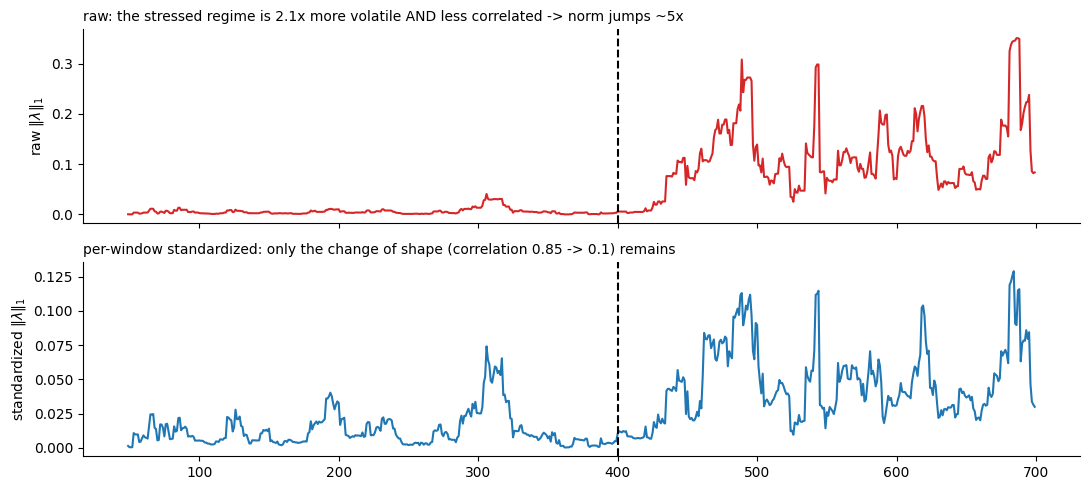

mean norm calm -> stress: raw 0.006 -> 0.126 (x21.6);  standardized 0.013 -> 0.052 (x4.1)


In [8]:
def norm_series_std(df, w=50):
    X = df.values; out = []
    for t in range(w - 1, len(X)):
        win = X[t - w + 1:t + 1]; win = (win - win.mean(0)) / win.std(0)
        out.append(T.landscape_norm(T.rips_h1(win), 1))
    return pd.Series(out, index=df.index[w - 1:])

raw = T.norm_series(S, w=50)["L1"]; std = norm_series_std(S, 50)
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(raw, color="C3"); axes[0].axvline(400, color="k", ls="--"); axes[0].set_ylabel("raw $\\|\\lambda\\|_1$")
axes[0].set_title("raw: the stressed regime is 2.1x more volatile AND less correlated -> norm jumps ~5x", fontsize=10, loc="left")
axes[1].plot(std, color="C0"); axes[1].axvline(400, color="k", ls="--"); axes[1].set_ylabel("standardized $\\|\\lambda\\|_1$")
axes[1].set_title("per-window standardized: only the change of shape (correlation 0.85 -> 0.1) remains", fontsize=10, loc="left")
plt.tight_layout(); save("05_scale_caveat")
print("mean norm calm -> stress: raw %.3f -> %.3f (x%.1f);  standardized %.3f -> %.3f (x%.1f)" % (
    raw.loc[:399].mean(), raw.loc[450:].mean(), raw.loc[450:].mean() / raw.loc[:399].mean(),
    std.loc[:399].mean(), std.loc[450:].mean(), std.loc[450:].mean() / std.loc[:399].mean()))

## 6. Why variance, autocorrelation and low-frequency power of the norm series?

The paper does **not** use the norm itself as the warning. It uses three rolling statistics of the norm series, borrowed from the *critical slowing down* literature (Scheffer et al. 2009, Nature): when a dynamical system approaches a tipping point, its recovery from small shocks becomes slower, so its fluctuations become

- larger (**variance** ↑),
- more persistent (**lag-1 autocorrelation** ↑),
- slower (**low-frequency spectral power** ↑).

The cleanest model of this is an AR(1) process $y_t=\phi\,y_{t-1}+\varepsilon_t$ whose $\phi$ drifts toward 1. Experiment: $\phi$ rises linearly from 0.2 to 0.95 over 1,500 steps; we compute the three rolling statistics with $L=300$.

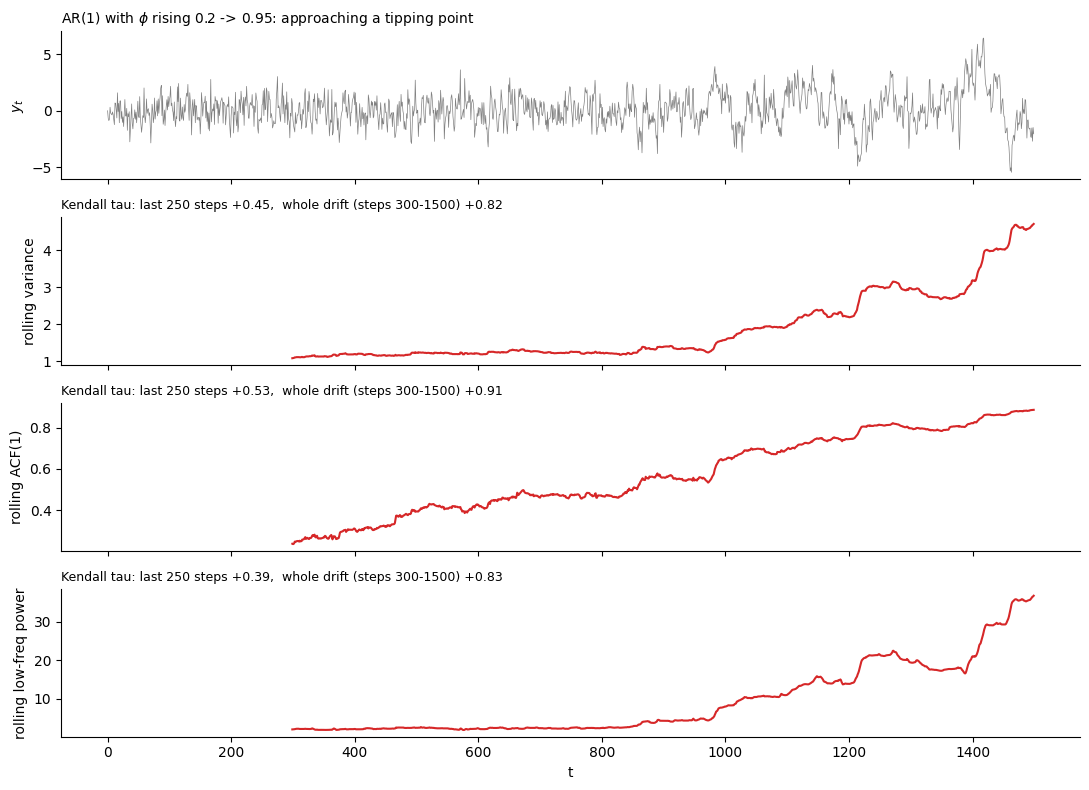

In [9]:
n = 1500; phi = np.linspace(0.2, 0.95, n); y = np.zeros(n); e = rng.normal(0, 1, n)
for t in range(1, n): y[t] = phi[t] * y[t - 1] + e[t]
y = pd.Series(y)
st = T.rolling_stats(y, L=300)
fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
axes[0].plot(y, lw=.5, color="gray"); axes[0].set_ylabel("$y_t$"); axes[0].set_title("AR(1) with $\\phi$ rising 0.2 -> 0.95: approaching a tipping point", loc="left", fontsize=10)
for ax, (col, lab) in zip(axes[1:], [("variance", "rolling variance"), ("acf1", "rolling ACF(1)"), ("lowfreq", "rolling low-freq power")]):
    ax.plot(st[col], color="C3"); ax.set_ylabel(lab)
    ax.set_title(f"Kendall tau: last 250 steps {T.kendall_trend(st[col].iloc[-250:]):+.2f},  whole drift (steps 300-1500) {T.kendall_trend(st[col].dropna()):+.2f}", loc="left", fontsize=9)
axes[-1].set_xlabel("t"); plt.tight_layout(); save("06_critical_slowing_down")

All three statistics rise over the whole drift ($\tau$ close to 1 over steps 300–1500) even though any single 250-step stretch can be flat or bumpy ($\tau\approx0.4$–$0.5$). That is the pattern the paper looks for in the norm series before a crash: not "the norm is high", but "the norm's fluctuations are getting bigger, slower and more persistent".

**Why Kendall $\tau$?** It is the fraction of pairs of days $(s&lt;t)$ with $z_s&lt;z_t$ minus the fraction with $z_s&gt;z_t$: a rank statistic, so it ignores the size of the statistic and outliers and only asks "is it going up?". $\tau=1$ means monotone increase.

**Why a null distribution is needed.** Consecutive windows share 49 of their 50 days, so the norm series is very persistent, and its 500-day rolling variance is smoother still: over any 250-day stretch it is either mostly going up or mostly going down. $|\tau|$ near 1 is then the *normal* outcome, not the exception. Experiment: 6,000 days of **iid** 3-dimensional returns (no information at all) pushed through the whole pipeline, then $\tau$ over random 250-day windows.

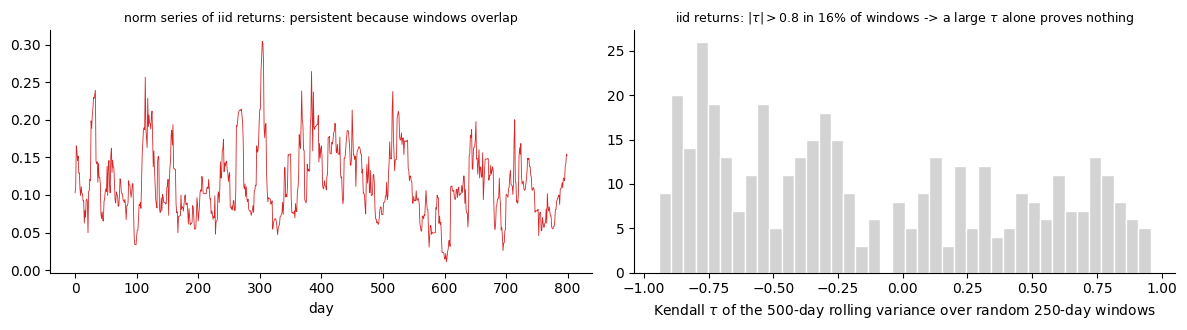

In [10]:
iid = pd.DataFrame(rng.normal(0, 1, (6000, 3)), columns=list("ABC"))
ns_iid = T.norm_series(iid, w=50)["L1"]
st = T.rolling_stats(ns_iid, L=500).dropna()
taus = [T.kendall_trend(st["variance"].iloc[s:s + 250]) for s in rng.integers(0, len(st) - 250, 400)]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(ns_iid.iloc[:800].values, lw=.6, color="C3"); axes[0].set_title("norm series of iid returns: persistent because windows overlap", fontsize=9); axes[0].set_xlabel("day")
axes[1].hist(taus, bins=40, color="lightgray", edgecolor="white"); axes[1].set_xlabel("Kendall $\\tau$ of the 500-day rolling variance over random 250-day windows")
axes[1].set_title("iid returns: $|\\tau|>0.8$ in %.0f%% of windows -> a large $\\tau$ alone proves nothing" % (100 * np.mean(np.abs(taus) > 0.8)), fontsize=9)
plt.tight_layout(); save("07_null_tau")

Even with returns that carry no information at all, one random window in six shows $|\tau|>0.8$. With real returns, whose volatility clusters, the share is far higher (in the Korean index analysis most random windows did). A reported $\tau$ therefore means something only next to the distribution of $\tau$ over random windows of the same series.

## 7. The pipeline end to end on one real window

To see what each stage actually produces, we take KOSPI / KOSPI 200 / KOSDAQ returns for 2019–2020 and show: the cloud of one calm window and one stressed window, their diagrams and landscapes, and the norm series with its rolling variance. No claims are made here; the analysis with events, null tests and a volatility benchmark lives in a separate notebook.

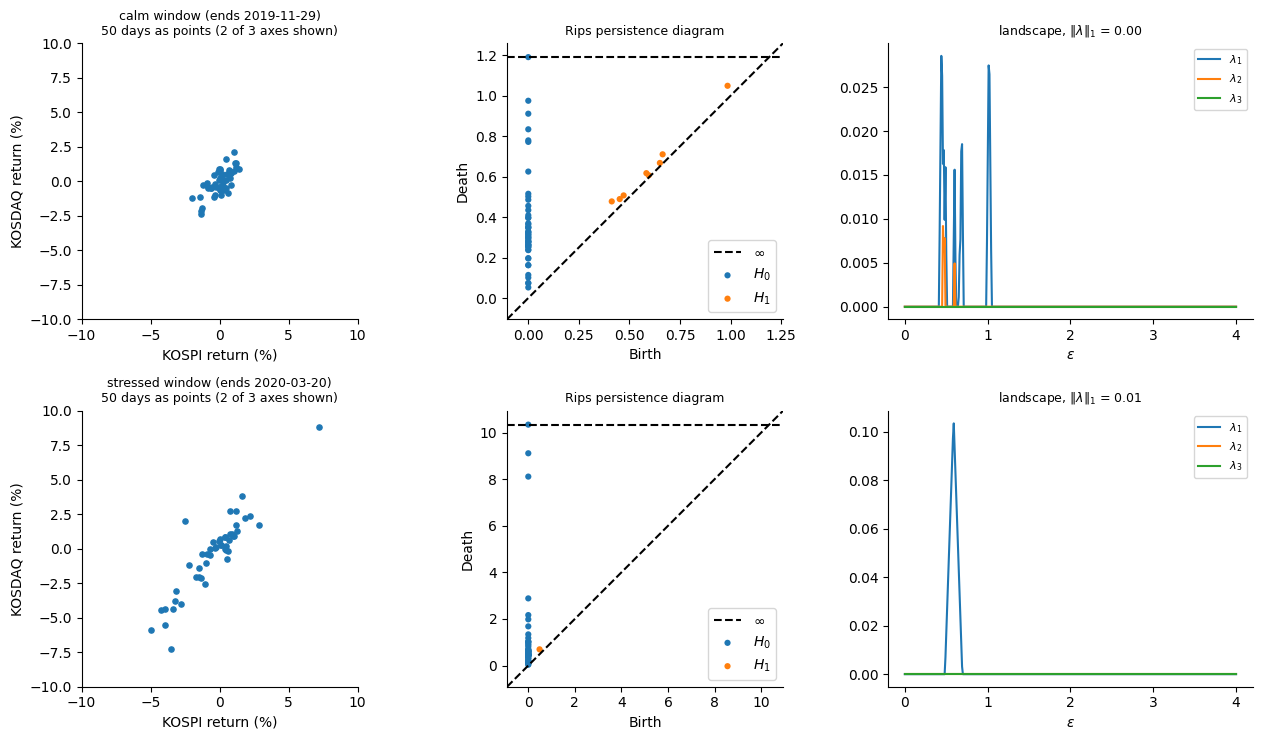

In [11]:
kr = pd.read_csv("data/kr_indices_raw.csv", index_col=0, parse_dates=True)
r = T.log_returns(kr.loc["2019":"2020"]) * 100
days = {"calm window (ends 2019-11-29)": "2019-11-29", "stressed window (ends 2020-03-20)": "2020-03-20"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
grid = np.linspace(0, 4, 400)
for row, (name, d) in zip(axes, days.items()):
    pos = r.index.get_indexer([pd.Timestamp(d)], method="pad")[0]; X = r.values[pos - 49:pos + 1]
    dg = T.rips_h1(X); lam = T.landscape(dg, grid, 3)
    row[0].scatter(X[:, 0], X[:, 2], s=14); row[0].set_xlabel("KOSPI return (%)"); row[0].set_ylabel("KOSDAQ return (%)"); row[0].set_xlim(-10, 10); row[0].set_ylim(-10, 10); row[0].set_aspect("equal")
    row[0].set_title(f"{name}\n50 days as points (2 of 3 axes shown)", fontsize=9)
    plot_diagrams(ripser(X, maxdim=1)["dgms"], ax=row[1], show=False); row[1].set_title("Rips persistence diagram", fontsize=9)
    for k in range(3): row[2].plot(grid, lam[k], label=f"$\\lambda_{k+1}$")
    row[2].set_title(f"landscape, $\\|\\lambda\\|_1$ = {T.landscape_norm(dg, 1):.2f}", fontsize=9); row[2].set_xlabel("$\\epsilon$"); row[2].legend(fontsize=8)
plt.tight_layout(); save("08_real_windows")

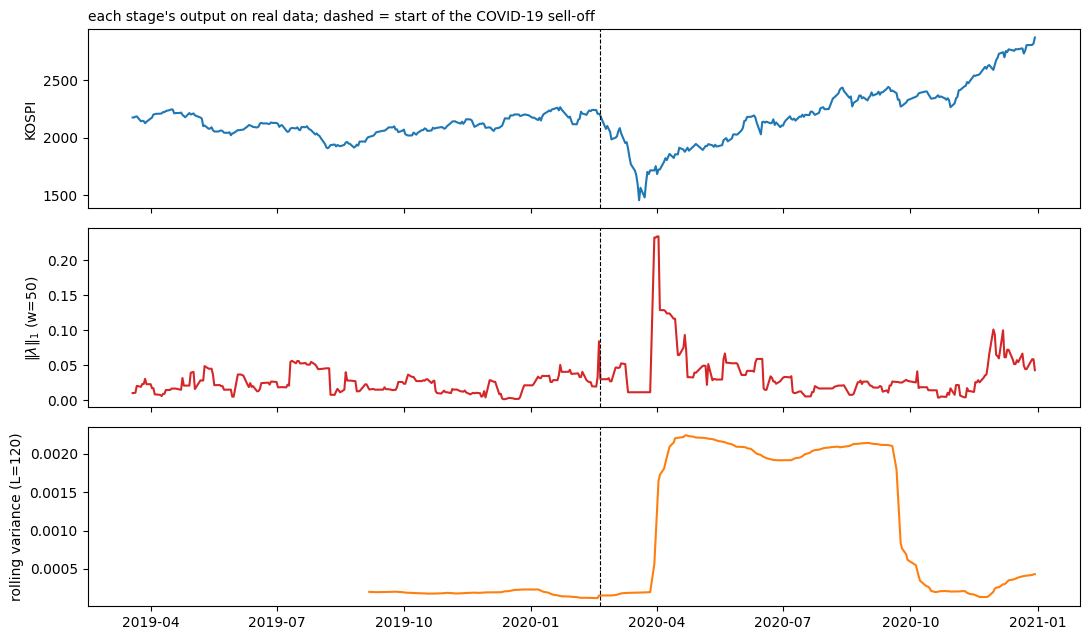

In [12]:
ns = T.norm_series(r, w=50); st = T.rolling_stats(ns["L1"], L=120)
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(kr.loc[ns.index[0]:ns.index[-1], "KOSPI"]); axes[0].set_ylabel("KOSPI")
axes[1].plot(ns["L1"], color="C3"); axes[1].set_ylabel("$\\|\\lambda\\|_1$ (w=50)")
axes[2].plot(st["variance"], color="C1"); axes[2].set_ylabel("rolling variance (L=120)")
for ax in axes: ax.axvline(pd.Timestamp("2020-02-20"), color="k", ls="--", lw=.8)
axes[0].set_title("each stage's output on real data; dashed = start of the COVID-19 sell-off", loc="left", fontsize=10)
plt.tight_layout(); save("09_real_series")

## 8. Two alternatives you will meet: Wasserstein distance between consecutive days, and zigzag persistence

**Level vs change.** The norm measures the *level* of loop structure in a window. The Wasserstein distance $W_p(D_t,D_{t+1})$ between consecutive diagrams measures how much the structure *changed* from one day to the next (points may be matched to the diagonal, so births and deaths are counted too). The two are complementary: a window can have a high norm that is stable, or a low norm that is changing fast.

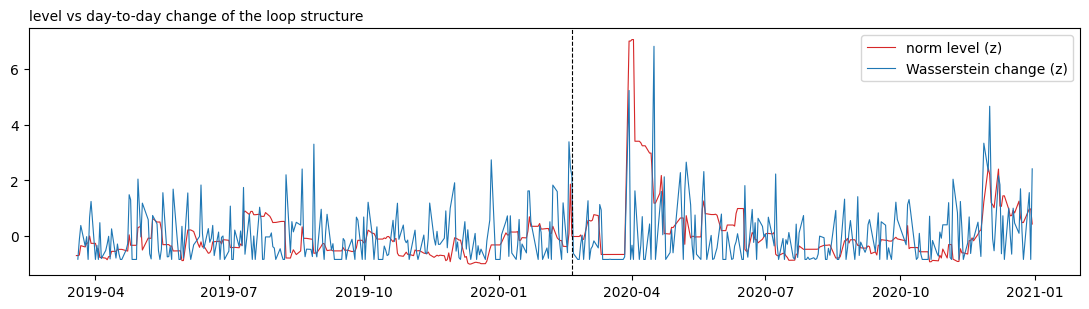

correlation of the two series: 0.21


In [13]:
W = []
dgms = [ripser(r.values[t - 49:t + 1], maxdim=1)["dgms"][1] for t in range(49, len(r))]
for a, b in zip(dgms[:-1], dgms[1:]):
    W.append(wasserstein(a, b))
W = pd.Series(W, index=r.index[50:])
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot((ns["L1"] - ns["L1"].mean()) / ns["L1"].std(), color="C3", lw=.8, label="norm level (z)")
ax.plot((W - W.mean()) / W.std(), color="C0", lw=.8, label="Wasserstein change (z)")
ax.axvline(pd.Timestamp("2020-02-20"), color="k", ls="--", lw=.8); ax.legend(); ax.set_title("level vs day-to-day change of the loop structure", loc="left", fontsize=10)
plt.tight_layout(); save("10_wasserstein")
print("correlation of the two series:", np.corrcoef(ns["L1"].iloc[1:], W)[0, 1].round(2))

**Zigzag persistence.** Standard persistence needs a *nested* sequence $K_1\subseteq K_2\subseteq\cdots$. Consecutive sliding windows are not nested: each day one point leaves and one enters. Zigzag persistence (Carlsson & de Silva 2010) allows arrows in both directions, $K_1\to K_1\cup K_2\leftarrow K_2\to\cdots$, and still has a well-defined barcode. The "union trick" in the attached LAMP report computes standard persistence of $X_t\cup X_{t+1}$, which is the middle object of exactly this zigzag; with windows that overlap in 49 of 50 points the union is almost the same cloud, which is why that report found no difference. Zigzag only pays off when consecutive clouds are genuinely different (e.g. non-overlapping windows).

In [14]:
# non-overlapping windows: the union of two consecutive 25-day clouds vs each cloud alone
w = 25; blocks = [r.values[t:t + w] for t in range(0, len(r) - w, w)]
alone = [T.landscape_norm(T.rips_h1(b), 1) for b in blocks]
union = [T.landscape_norm(T.rips_h1(np.r_[a, b]), 1) for a, b in zip(blocks[:-1], blocks[1:])]
print("mean L1 of a 25-day cloud: %.3f;  of the union of two consecutive clouds: %.3f" % (np.mean(alone), np.mean(union)))
print("fraction of 25-day clouds with no loop at all: %.0f%%;  of unions: %.0f%%" % (100 * np.mean(np.array(alone) == 0), 100 * np.mean(np.array(union) == 0)))

mean L1 of a 25-day cloud: 0.009;  of the union of two consecutive clouds: 0.019
fraction of 25-day clouds with no loop at all: 16%;  of unions: 0%


## 9. Summary: the "why" of each step

| step | why | what to watch |
|---|---|---|
| log returns, one point per day | comparable across time and axes | rescale axes with different units |
| sliding window $w\approx50$ | one cloud per day; enough points for loops, short enough to react | small $w$ = noise, large $w$ = lag |
| Vietoris–Rips, Euclidean | needs only distances; within factor 2 of Čech | convention $d\le\epsilon$ |
| $H_1$ | lowest dimension that sees shape beyond spread | $H_0$ ≈ volatility, $H_2$ needs more points |
| landscape | a function: can be averaged, has norms, is stable | drop the infinite $H_0$ bar |
| $\|\lambda\|_1,\|\lambda\|_2$ | one number; $L^1$ counts all loops, $L^2$ the big ones | scales with volatility squared |
| rolling variance / ACF / low-freq | critical slowing down before a transition | needs $L$ long enough, lags by $L$ |
| Kendall $\tau$ | rank-based trend test | bimodal null: always report random-window $\tau$ |